In [1]:
DS_DIR = "208735" #208735 159090 73131
DAY_DIR = "2026_06_04"

In [2]:
import os
from pathlib import Path
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import utils

In [3]:
FEA_DIR = utils.FEA_DIR
RQ = "RQ3"

In [4]:

ROOT = Path("..")

OUT_DIR = "ImgOut"
OUT = ROOT / OUT_DIR / DAY_DIR / RQ / DS_DIR
OUT.mkdir(parents=True, exist_ok=True)
OUT_CSV = OUT / "CSV"
OUT_CSV.mkdir(parents=True, exist_ok=True)
OUT_PDF = OUT / "PDF"
OUT_PDF.mkdir(parents=True, exist_ok=True)
OUT_PNG = OUT / "PNG"
OUT_PNG.mkdir(parents=True, exist_ok=True)
INPUT = OUT / "INPUT"

ROB_DIR = ROOT / DAY_DIR / DS_DIR


sns.set_theme(style="white", font_scale=0.9)

In [5]:
for el in sorted(os.listdir(ROB_DIR)):
    if 'k0_iter1' in el:
        break
BASE = os.path.join(ROB_DIR, el)


dea_files, wgcna_files = utils.read_files(BASE)

dea_labels = [str(utils.dea_thr(f)) for f in dea_files]  # e.g. 50, 60, ... 150
dea_labels = [str(int(x)/100) for x in dea_labels]
wgcna_labels = [f"{a}_{b}" for (a, b) in map(utils.wgcna_thr, wgcna_files)]  # e.g. 60_60, 65_65, ...
wgcna_labels = [f'{int(x[:2])/100:.2f}' for x in wgcna_labels]

# -----------------------------
# Read sets
# -----------------------------
dea_sets = [utils.read_gene_set(os.path.join(BASE, f)) for f in dea_files]
wgcna_sets = [utils.read_gene_set(os.path.join(BASE, f)) for f in wgcna_files]

J_cross = utils.compute_cross_jaccard(wgcna_sets, dea_sets)
df_cross = pd.DataFrame(J_cross, index=wgcna_labels, columns=dea_labels)


In [6]:
dea_sizes = [len(x) for x in dea_sets]
wgcna_sizes = [len(x) for x in wgcna_sets]

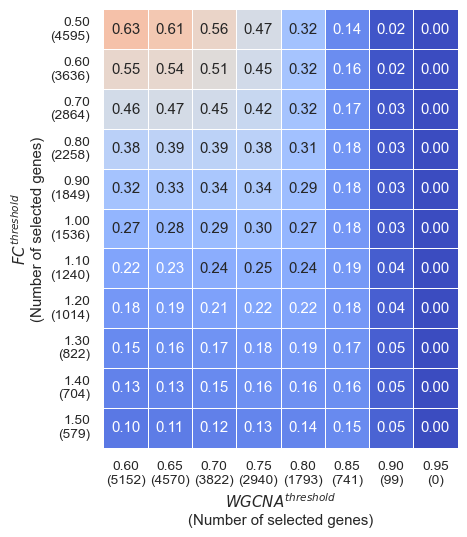

In [7]:
def _format_threshold_label(x, approach):
    if approach == "wgcna":
        x = str(x).split("_")[0]
    else:
        x = str(x)

    try:
        if "." in x:
            return f"{float(x):.2f}"
        else:
            return f"{int(x) * 0.01:.2f}"
    except:
        return str(x)


def jaccard_heatmap(df_cross, dea_count, wgcna_count):
    # dopo il transpose:
    # - asse x = WGCNA = df_cross.index
    # - asse y = DEA   = df_cross.columns

    x_vals = list(df_cross.index)
    y_vals = list(df_cross.columns)

    x_labels = [
        f"{_format_threshold_label(x, 'wgcna')}\n({c})"
        for x, c in zip(x_vals, wgcna_count)
    ]
    y_labels = [
        f"{_format_threshold_label(y, 'dea')}\n({c})"
        for y, c in zip(y_vals, dea_count)
    ]

    fig, ax = plt.subplots(figsize=(len(df_cross.T.columns) * 0.6, len(df_cross.T.index) * 0.5))

    sns.heatmap(
        df_cross.T,
        ax=ax,
        vmin=0,
        vmax=1,
        square=False,
        cmap="coolwarm",
        cbar=False,
        annot=True,
        fmt=".2f",
        linewidths=0.5,
        linecolor="white",
        xticklabels=x_labels,
        yticklabels=y_labels
    )
    name_w = utils.APPROACH_SPECS["WGCNA"]["param_name"]
    name_d = utils.APPROACH_SPECS["DEA"]["param_name"]
    ax.set_xlabel(f"{name_w}\n(Number of selected genes)")
    ax.set_ylabel(f"{name_d}\n(Number of selected genes)")

    ax.tick_params(axis="x", rotation=0)
    ax.tick_params(axis="y", rotation=0)

    plt.tight_layout()
    plt.savefig(os.path.join(OUT_PNG, f'{RQ}_{DS_DIR}_CROSS_jaccard.png'),
                format='png', dpi=300, bbox_inches='tight')
    plt.savefig(os.path.join(OUT_PDF, f'{RQ}_{DS_DIR}_CROSS_jaccard.pdf'),
                format='pdf', bbox_inches='tight')
    plt.show()
jaccard_heatmap(df_cross, dea_sizes, wgcna_sizes)

/var/folders/27/y8zb96dj4rz5c5pd6d84yd440000gn/T/ipykernel_29671/700185337.py:21: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


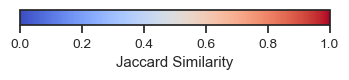

In [8]:
import matplotlib as mpl
def save_colorbar(label="Jaccard Similarity",
                  cmap="coolwarm",
                  vmin=0,
                  vmax=1,
                  orientation="horizontal",
                  filename_prefix="colorbar_jaccard"):
    
    norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
    sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])

    if orientation == "vertical":
        fig, ax = plt.subplots(figsize=(1.2, 10))
    else:
        fig, ax = plt.subplots(figsize=(4, 0.2))

    cbar = fig.colorbar(sm, cax=ax, orientation=orientation)
    cbar.set_label(label)

    plt.tight_layout()

    plt.savefig(
        os.path.join(OUT_PNG, f"{filename_prefix}.png"),
        format="png", dpi=300, bbox_inches="tight"
    )
    plt.savefig(
        os.path.join(OUT_PDF, f"{filename_prefix}.pdf"),
        format="pdf", bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)
save_colorbar()

# GOntoSim

In [9]:
def plot_heatmap(mean_matrix, go_category, go_count_a, go_count_b):
    annot = mean_matrix.copy().astype(object)
    
    x_labels = [x.split("_")[0] for x in mean_matrix.columns]
    x_labels = [f"{int(x)*0.01:.2f}" for x in x_labels]
    x_labels = [f"{x}\n({y})" for x, y in zip(x_labels, go_count_b)]

    y_labels = mean_matrix.index
    y_labels = [f"{int(x)*0.01:.2f}" for x in y_labels]
    y_labels = [f"{x}\n({y})" for x, y in zip(y_labels, go_count_a)]
    
    fig, ax = plt.subplots(
        figsize=(len(mean_matrix.columns)*0.6, len(mean_matrix.index)*0.5)
    )

    sns.heatmap(
        mean_matrix,
        ax=ax,
        annot=annot,
        fmt=".2f",
        cmap="coolwarm",
        vmin=0,
        vmax=1,
        square=True,
        linewidths=0.5,
        xticklabels=x_labels,
        yticklabels=y_labels,
        linecolor="white",
        cbar=False
    )

    name_w = utils.APPROACH_SPECS["WGCNA"]["param_name"]
    name_d = utils.APPROACH_SPECS["DEA"]["param_name"]

    ax.set_xlabel(f"{name_w}\n(Number of GO Terms)")
    ax.set_ylabel(f"{name_d}\n(Number of GO Terms)")

    ax.set_xticklabels(x_labels, rotation=0, ha="center")
    ax.set_yticklabels(y_labels, rotation=0, va="center")

    plt.tight_layout()

    fig.savefig(
        os.path.join(OUT_PNG, f'{RQ}_{DS_DIR}_CROSS_{go_category}.png'),
        format='png',
        dpi=300,
        bbox_inches='tight'
    )

    fig.savefig(
        os.path.join(OUT_PDF, f'{RQ}_{DS_DIR}_CROSS_{go_category}.pdf'),
        format='pdf',
        bbox_inches='tight'
    )

    plt.show()
    plt.close(fig)

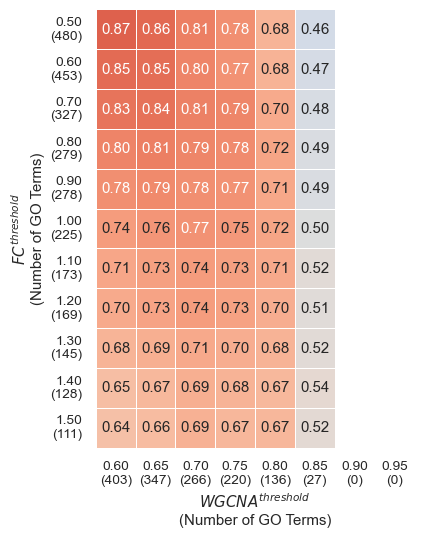

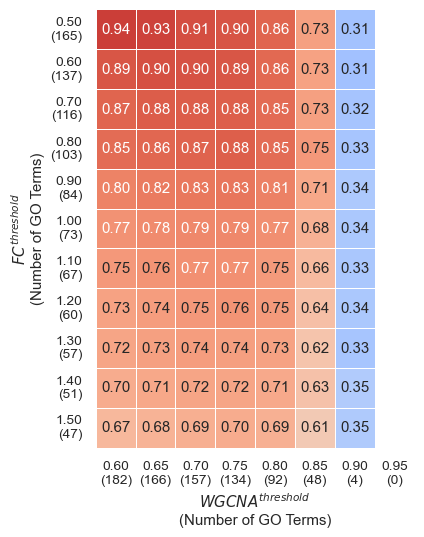

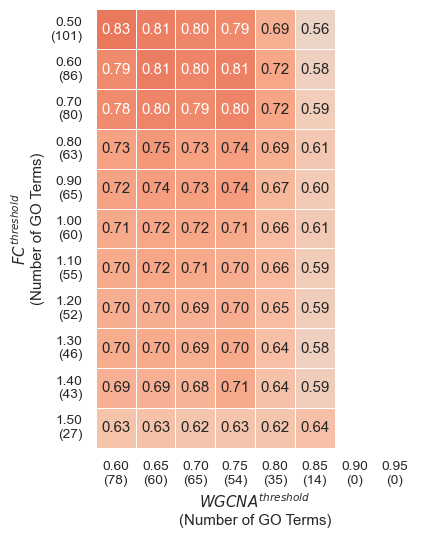

In [10]:
for run in os.listdir(ROB_DIR):
    final_dir = ROB_DIR / run / FEA_DIR

    if "k0" in run:
        for category in utils.GO_CATEGORY_MAP:
            go_counts = []
            for approach in ["DEA", "WGCNA"]:
                params = utils.APPROACH_SPECS[approach]["param_int"]
    
                go_count = []

                for param in params:
                    if approach == 'DEA':                
                        df = pd.read_csv(final_dir / f"{approach}_go_{param}.csv")
                    elif approach == 'WGCNA':                
                        df = pd.read_csv(final_dir / f"{approach}_go_{param}_{param}.csv")
                    terms = (
                        df[df.Category == category]["Term"]
                        .dropna()
                        .sort_values()
                        .reset_index(drop=True)
                    )
                    # salva CSV
                    out_file = OUT_CSV / f"{RQ}_{DS_DIR}_{approach}_go_{param}_{category}.csv"
                    df_terms = terms.to_frame(name="Term")
                    df_terms.to_csv(out_file, index=False)
                    go_count.append(len(df_terms))
                go_counts.append(go_count)

            fname = INPUT / f"{RQ}_{DS_DIR}_{utils.GO_CATEGORY_MAP[category]}_cross_mean_similarity.csv"
            df = pd.read_csv(fname, index_col = 0)

            plot_heatmap(df, category, go_counts[0], go_counts[1])